In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from tifffile import imread
import kemstem
from matplotlib.colors import LinearSegmentedColormap

%matplotlib widget
print(f'{kemstem.__version__=}')

kemstem.__version__='0.0.6'


# Data loading and preprocessing

Image shape (2041, 2029)
Cropped to (2029, 2029)
Normalized to min: 0.0, max: 1.0


(np.float64(-0.5), np.float64(2028.5), np.float64(2028.5), np.float64(-0.5))

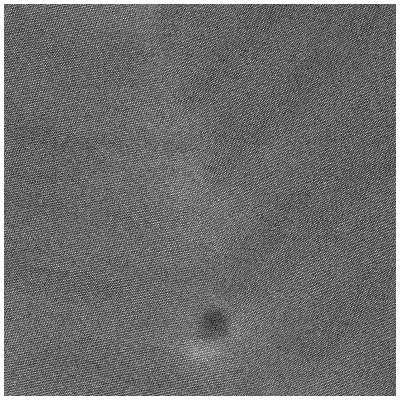

In [3]:
filename = '/Users/noahschnitzer/Documents/kem/deliverables/others/20250101_Henri_MnAlCu/data/20250314_1302 1.9 Mx A_HAADF_registered.tif'
im = imread(filename)
print(f'Image shape {im.shape}')
im = im[:min(im.shape),:min(im.shape)]
print(f'Cropped to {im.shape}')
im = kemstem.util.normalize(im)
print(f'Normalized to min: {im.min()}, max: {im.max()}')

fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(4,4))
ax.matshow(im,cmap='gray')
ax.axis('off')

(np.float64(-0.5), np.float64(2028.5), np.float64(2028.5), np.float64(-0.5))

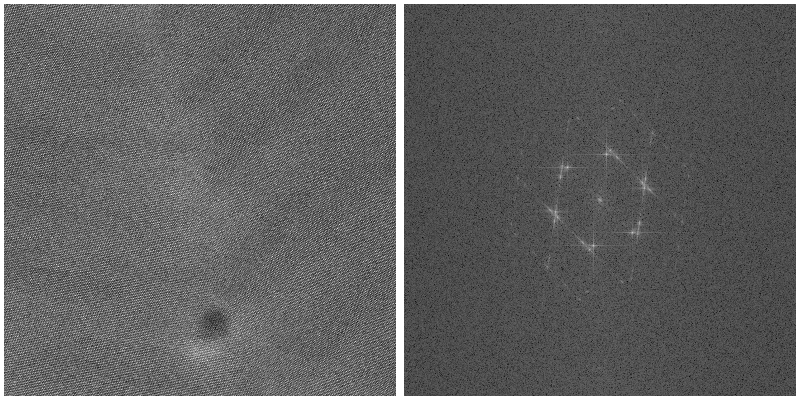

In [4]:
cft = kemstem.prepare_fourier_pattern(im)
lft = kemstem.prepare_fourier_pattern(im,log=True,log_offset=1e0) # Here we also take a log transform of the FFT for ease of visualization

fig,ax = plt.subplots(1,2,constrained_layout=True,figsize=(8,4))
ax[0].matshow(im,cmap='gray')
ax[0].axis('off')
ax[1].matshow(lft,cmap='gray')
ax[1].axis('off')

# Identifying FFT peaks of interest
Here we can select one low order in-plane and one out-of-plane peak in the FFT to analyze the relaxation of the film.

The next cell allows these peaks to be picked manually, or uncomment the following cell to use a preselected set of peak positions.

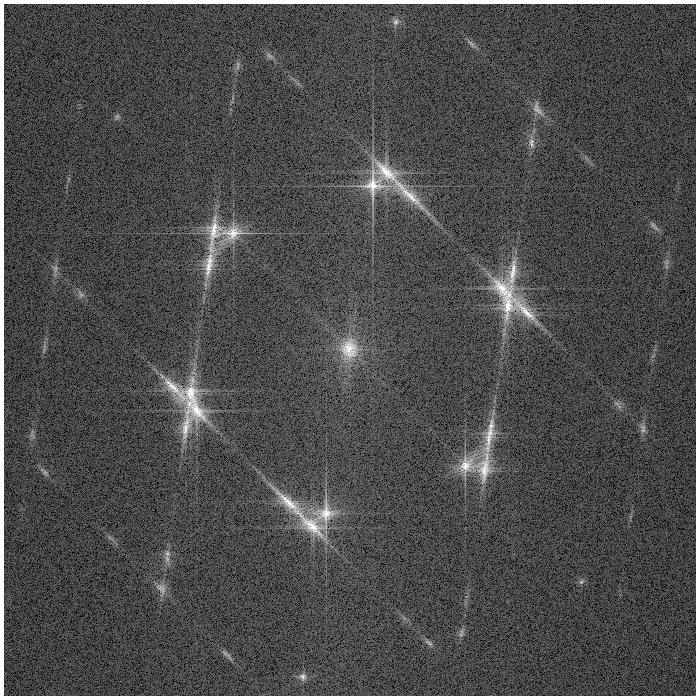

In [9]:
preselected = np.array([[ 845.90904841,  845.49222684],
       [ 841.88213058,  818.92323431],
       [ 890.62777044,  810.66697439],
       [ 776.73949169, 1048.12418244],
       [ 758.57538003, 1067.85508415],
       [ 792.08764233, 1101.49777001]])

zoom = 500 # crop the pattern to display only the center area (with radius set by zoom in pixels) with useful information

# to select peaks by hand, change the preselected argument below to None
selected_peaks = kemstem.select_peaks(lft,preselected=None,zoom=zoom,select_conjugates=False,
                                      figsize=(7,7),delete_within=5,vmin=3,vmax=9,)

# Fitting FFT peaks
Next, we fit the peaks using 2D gaussians. Here only the peak positions are important, so just refining them with e.g. center of mass is also reasonable.

These peak positions are quite important as they will essentially serve as without further adjustment they will serve as the reference parameters for the following phase and strain measurements. It may be interesting to adjust the peak guess positions and/or fit parameters to test the effect of mapping the film peak, the substrate peak, and the position between the two.

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 167.23it/s]


array([[ 845.90904841,  845.49222684],
       [ 841.88213058,  818.92323431],
       [ 890.62777044,  810.66697439],
       [ 776.73949169, 1048.12418244],
       [ 758.57538003, 1067.85508415],
       [ 792.08764233, 1101.49777001]])

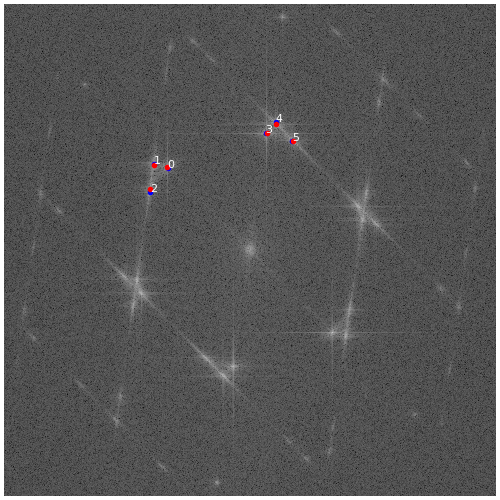

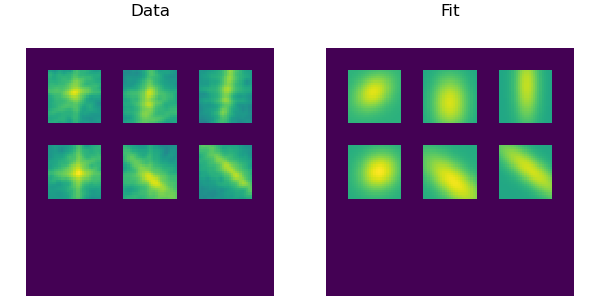

In [10]:
p0 = np.array(selected_peaks).T

peaks_ref,errs,opts,data_fits  = kemstem.refine_peaks_gf(gaussian_filter(lft,1), p0, window_dimension=25, remove_unfit = False)
fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(5,5))
kemstem.plot_numbered_points(lft,p0,ax=ax,color='b',zoom=zoom)
ax.plot(peaks_ref[:,1],peaks_ref[:,0],'r.')
ax.axis('off')

_ = kemstem.util.plot_fit_comparison(data_fits,)

peaks_ref

# Fourier Filtering
One of the peaks picked and refined previously can be selected for filtering with the `peak_index` variable. For filtering, the key parameter in addition to the peak position is the width of the gaussian profile applied around the peak in the FFT to select it - this width will be inversely proportional to the resulting resolution or coarsening length of the fourier filtered signal and its derivatives (the extracted phase and strain maps), but choosing too large of a filter will incorporate harmful noise in the filtered signal. This is set with the `sigma` variable that determines the standard deviation of the gaussian profile in k-space. The real space coarsening length corresponding to this filter size is visualized with the black and white coarsening markers in the bottom right of the images. 

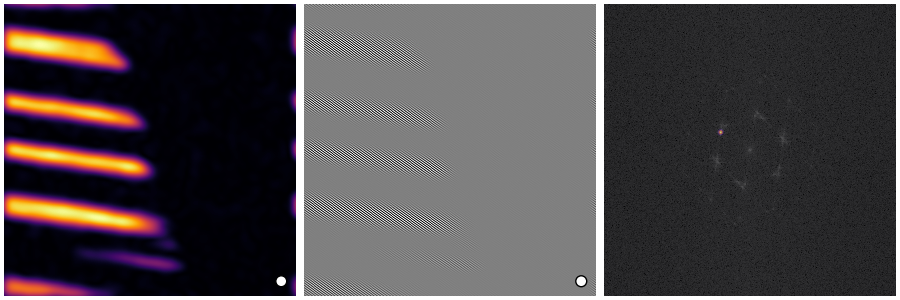

In [27]:
peak_index = 2
sigma= 10
filtered_im, filtered_ft, mask = kemstem.fourier_filter(cft,peaks_ref[peak_index,:],sigma=sigma)

fig,ax = plt.subplots(1,3,constrained_layout=True,figsize=(9,3))
ax[0].matshow(np.abs(filtered_im),cmap='inferno',alpha=1)
ax[0].axis('off')
ax[1].matshow(np.real(filtered_im),cmap='gray')
ax[1].axis('off')
ax[2].matshow(lft,cmap='gray')
ax[2].matshow(mask,alpha=.5,cmap='inferno')
ax[2].axis('off')

kemstem.util.coarsening_marker(ax[0],kemstem.coarsening_length(im.shape[0],sigma),edgecolor='k',facecolor='w')
kemstem.util.coarsening_marker(ax[1],kemstem.coarsening_length(im.shape[0],sigma),edgecolor='k',facecolor='w')

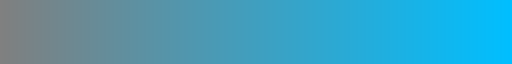

In [48]:
filtered_im_normalized = kemstem.normalize(np.abs(filtered_im))

my_colormap = LinearSegmentedColormap.from_list("to_color", ['grey','deepskyblue'])
my_colormap

[]

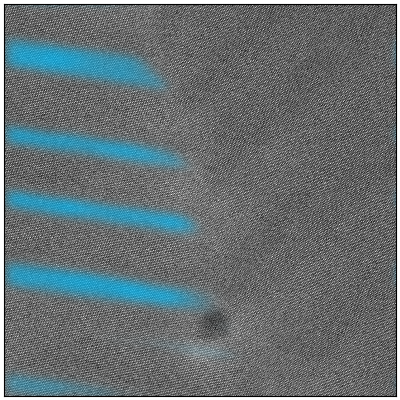

In [49]:

fig,ax = plt.subplots(1,1,constrained_layout=True,figsize=(4,4))
ax.matshow(im,cmap='gray')
ax.matshow(filtered_im_normalized,cmap=my_colormap,alpha=.7*filtered_im_normalized)
ax.set_xticks([])
ax.set_yticks([])

[]

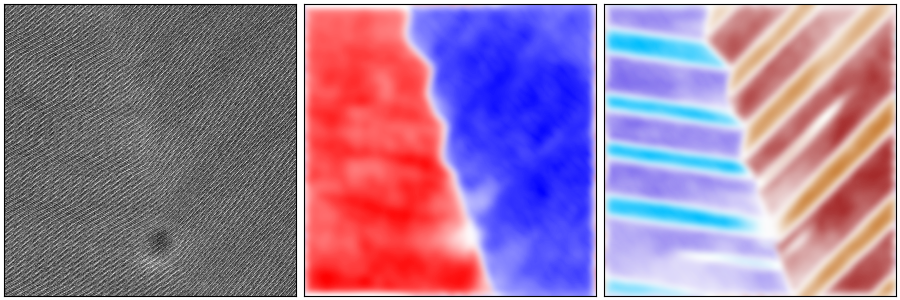

In [51]:
filtered_norm_images = [kemstem.util.normalize(np.abs(kemstem.fourier.fourier_filter(cft,p,sigma=10)[0])) 
                        for p in peaks_ref]
colors = ['blue','mediumslateblue','deepskyblue','red','brown','peru']
cmps = [LinearSegmentedColormap.from_list("to_color", ['white',color]) for color in colors]

fig,ax = plt.subplots(1,3,figsize=(9,3),constrained_layout=True)
ax[0].matshow(im,cmap='gray')

ax[1].matshow(filtered_norm_images[0],cmap=cmps[0],alpha=filtered_norm_images[0])
ax[1].matshow(filtered_norm_images[3],cmap=cmps[3],alpha=filtered_norm_images[3])

ax[2].matshow(filtered_norm_images[1],cmap=cmps[1],alpha=filtered_norm_images[1])
ax[2].matshow(filtered_norm_images[2],cmap=cmps[2],alpha=filtered_norm_images[2])
ax[2].matshow(filtered_norm_images[4],cmap=cmps[4],alpha=filtered_norm_images[4])
ax[2].matshow(filtered_norm_images[5],cmap=cmps[5],alpha=filtered_norm_images[5])
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].set_xticks([])
ax[1].set_yticks([])
ax[2].set_xticks([])
ax[2].set_yticks([])